# Experiment 10: Complete ANN-Based Classification System

**Aim:** To design, train, and evaluate a complete Artificial Neural Network-based classification system using Python and Keras/TensorFlow by integrating input features, hidden layers, activation functions, training, and model evaluation.

**Theory:**

This experiment brings together every concept covered in this module:

- Input features (Experiment 1, 2)
- Activation functions: ReLU (hidden layers), Softmax (output layer) (Experiment 3)
- A multi-layer architecture (Experiment 4, 5)
- Training via Gradient Descent + Backpropagation, handled internally by Keras' Adam optimizer (Experiment 6, 7, 8)
- Full performance evaluation using multiple metrics (Experiment 9)

**Dataset:** The Wine dataset (built into scikit-learn) — a 3-class classification problem based on 13 chemical measurements of wine samples.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

tf.random.set_seed(42)
np.random.seed(42)

I0000 00:00:1788702137.456208    4758 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788702137.456813    4758 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1788702138.982621    4758 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788702138.983030    4758 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Step 1: Load, split, and scale the dataset

In [2]:
data = load_wine()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

class_names = data.target_names
num_features = X.shape[1]
num_classes = len(class_names)
print(f"Features: {num_features} | Classes: {num_classes} -> {list(class_names)}")

Features: 13 | Classes: 3 -> [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


### Step 2: Design the ANN architecture
Input → Hidden(32, ReLU) → Hidden(16, ReLU) → Output(Softmax)

In [3]:
model = keras.Sequential([
    layers.Input(shape=(num_features,)),
    layers.Dense(32, activation="relu", name="hidden_layer_1"),
    layers.Dense(16, activation="relu", name="hidden_layer_2"),
    layers.Dense(num_classes, activation="softmax", name="output_layer"),
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,027 (4.01 KB)

 Trainable params: 1,027 (4.01 KB)

 Non-trainable params: 0 (0.00 B)

### Step 3: Train the ANN using backpropagation + gradient descent (Adam optimizer)

In [4]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=8,
    verbose=0,
)
print("Training complete.")

Training complete.


### Step 4: Evaluate the trained ANN using multiple metrics

In [5]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=class_names)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f} (sklearn check: {acc:.4f})")
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", report)

Test Loss     : 0.0212
Test Accuracy : 1.0000 (sklearn check: 1.0000)

Confusion Matrix:
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:
               precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



### Step 5: Visualize training curves and the confusion matrix

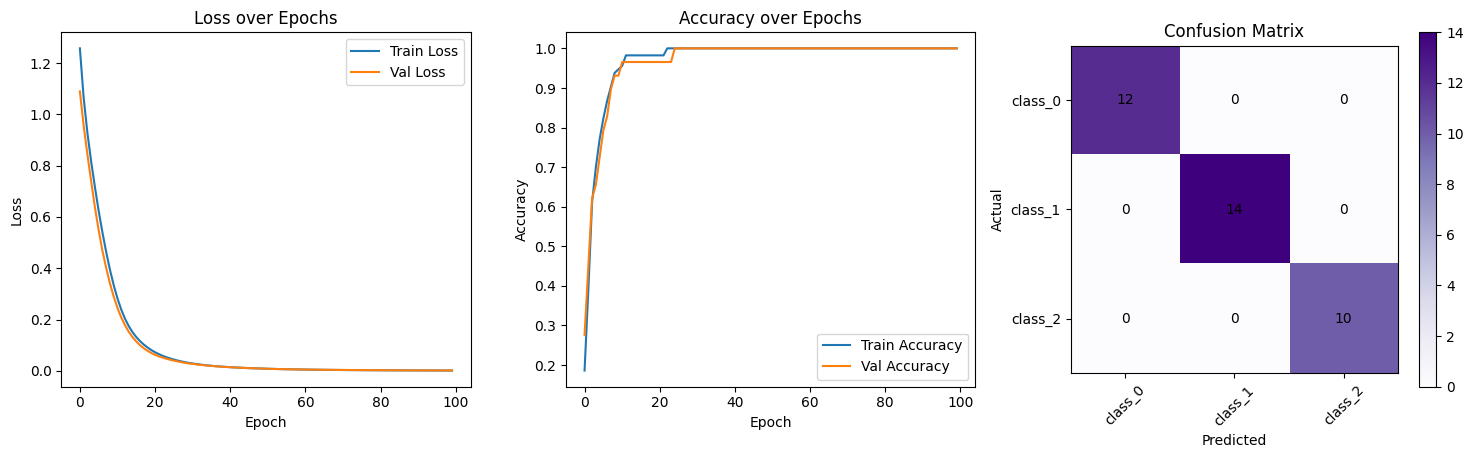

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss over Epochs")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy over Epochs")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

im = axes[2].imshow(cm, cmap="Purples")
axes[2].set_title("Confusion Matrix")
axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Actual")
axes[2].set_xticks(range(len(class_names))); axes[2].set_xticklabels(class_names, rotation=45)
axes[2].set_yticks(range(len(class_names))); axes[2].set_yticklabels(class_names)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[2].text(j, i, cm[i, j], ha="center", va="center", color="black")
fig.colorbar(im, ax=axes[2])

plt.tight_layout()
plt.savefig("complete_ann_results.png", dpi=150)
plt.show()

### Conclusion
By integrating input features, hidden layers with ReLU activations, a softmax output layer, backpropagation-based training via the Adam optimizer, and a full evaluation suite, this notebook demonstrates a complete, end-to-end ANN-based classification system achieving high accuracy on the 3-class Wine dataset.